# HW5 — Sales Data Cleaning and Analysis

**Web-Based Systems · Chapter 6**  
**Dataset:** `sales_data.csv`  
**Student:** *Enter your name and student ID before submission*

This notebook follows the seven stages specified in **CE-WebSystem-L8-2**, and uses only the supplied sales dataset. Run **Kernel → Restart Kernel and Run All Cells** before submission.

## ① Load the data and convert date columns
Read `sales_data.csv`; convert `order_date`, `shipping_date`, and `delivery_date` to datetime. The expected original shape is **(1030, 14)**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import platform

# Use the appropriate font when running on a Korean-language computer.
font_by_os = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}
plt.rcParams["font.family"] = font_by_os.get(platform.system(), "DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False

df = pd.read_csv("sales_data.csv")
for column in ["order_date", "shipping_date", "delivery_date"]:
    df[column] = pd.to_datetime(df[column], errors="coerce")

print("① Original shape:", df.shape)
print("Missing values:")
print(df[["customer_age", "satisfaction", "delivery_date"]].isna().sum().to_string())
assert df.shape == (1030, 14)


① Original shape: (1030, 14)
Missing values:
customer_age     51
satisfaction     30
delivery_date     5


## ② Remove duplicate rows
Remove exact duplicate records, keeping the first copy. **Expected:** `1030 -> 1004`. Missing ages, satisfaction ratings and delivery dates are **left missing** because guessing their values could distort results.

In [2]:
before = len(df)
df = df.drop_duplicates().copy()
print("② Duplicates:", before, "->", len(df))
assert (before, len(df)) == (1030, 1004)


② Duplicates: 1030 -> 1004


## ③ Restore incorrect quantities
When `quantity > 100`, use the verified relation `total_sales = quantity × unit_price` to restore the quantity as a rounded integer. This corrects **22 rows** without deleting the orders.

In [3]:
bad = df["quantity"] > 100
restored = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
df.loc[bad, "quantity"] = restored

diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("③ Corrected rows:", int(bad.sum()))
print("   Maximum quantity:", int(df["quantity"].max()))
print("   Sales amount mismatches (> 1 KRW):", int((diff > 1).sum()))
assert int(bad.sum()) == 22
assert int(df["quantity"].max()) == 99
assert int((diff > 1).sum()) == 0


③ Corrected rows: 22
   Maximum quantity: 99
   Sales amount mismatches (> 1 KRW): 0


## ④ Flag date errors and save cleaned data
If the delivery date is earlier than the shipping date, set `date_error=True`. **Do not invent a corrected date**: there is no evidence which of the two dates is wrong. Save `sales_clean.csv`. **Expected:** 147 errors, shape `(1004, 15)`.

In [4]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
df.to_csv("sales_clean.csv", index=False)
print("④ Date errors:", int(df["date_error"].sum()))
print("   Cleaned shape:", df.shape)
print("   Saved: sales_clean.csv")
assert int(df["date_error"].sum()) == 147
assert df.shape == (1004, 15)


④ Date errors: 147
   Cleaned shape: (1004, 15)
   Saved: sales_clean.csv


## ⑤ What is a typical delivery duration?
**Question:** How many days usually pass between `shipping_date` and `delivery_date`? Exclude `date_error=True` and missing dates, calculate days, show the histogram, then investigate the rightmost group using `days[days > 300]`.

⑤ Valid delivery-date rows: 852
   Mean (all valid dates): 22.05 days
   Median (all valid dates): 2.0 days


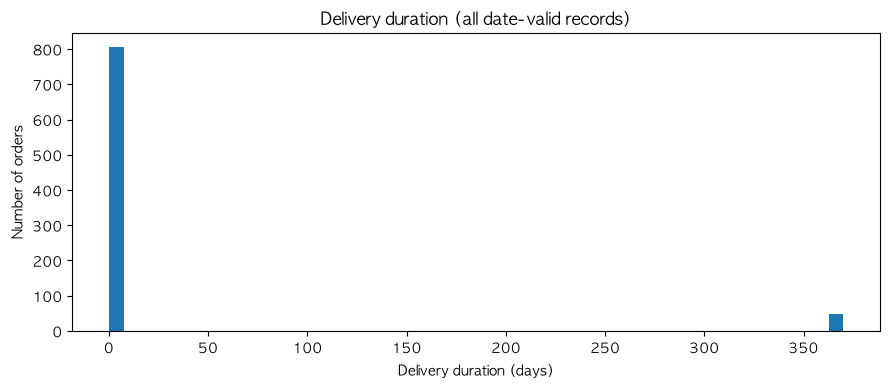

Orders with delivery duration > 300 days: 47
Range of these durations: 364 to 370 days


,shipping_date,delivery_date,days,status
11,2023-01-15,2024-01-15,365,배송완료
20,2023-01-23,2024-01-27,369,배송완료
29,2023-02-03,2024-02-03,365,배송완료
41,2023-02-14,2024-02-17,368,배송완료
68,2023-03-14,2024-03-12,364,배송완료
99,2023-04-11,2024-04-12,367,배송완료
110,2023-04-25,2024-04-24,365,배송완료
131,2023-05-13,2024-05-16,369,배송완료
165,2023-06-16,2024-06-18,368,배송완료
192,2023-07-13,2024-07-14,367,배송중


Typical-duration sample: 805
Mean excluding >300-day cluster: 1.93 days
Median excluding >300-day cluster: 2.0 days


In [5]:
valid_delivery = df.loc[
    (~df["date_error"]) & df["shipping_date"].notna() & df["delivery_date"].notna()
].copy()
valid_delivery["days"] = (
    valid_delivery["delivery_date"] - valid_delivery["shipping_date"]
).dt.days

days = valid_delivery["days"]
print("⑤ Valid delivery-date rows:", len(days))
print("   Mean (all valid dates):", round(days.mean(), 2), "days")
print("   Median (all valid dates):", round(days.median(), 2), "days")

plt.figure(figsize=(9, 4))
plt.hist(days, bins=50)
plt.title("Delivery duration (all date-valid records)")
plt.xlabel("Delivery duration (days)")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.show()

long_days = valid_delivery.loc[valid_delivery["days"] > 300,
    ["shipping_date", "delivery_date", "days", "status"]]
print("Orders with delivery duration > 300 days:", len(long_days))
print("Range of these durations:", int(long_days["days"].min()), "to", int(long_days["days"].max()), "days")
display(long_days.head(10))

# Outliers are excluded only for the 'typical delivery' estimate, not from sales_clean.csv.
typical_days = days[days <= 300]
print("Typical-duration sample:", len(typical_days))
print("Mean excluding >300-day cluster:", round(typical_days.mean(), 2), "days")
print("Median excluding >300-day cluster:", round(typical_days.median(), 2), "days")


**⑤ Answer (two lines):** The 852 records with nonmissing, nonreversed dates have a **mean of 22.05 days** and **median of 2 days**; the rightmost histogram group contains **47 orders** lasting roughly one year.  
The one-year cluster (364–370 days) may reflect date-entry problems but cannot be verified, so I retain those rows in `sales_clean.csv` and exclude them **only** when estimating a typical duration: **mean 1.93 days, median 2 days** for 805 orders.

## ⑥ Does lower satisfaction mean more returns?
**Question:** Compare the return rate for satisfaction levels 1–5. Define a return as `status == "반품"`, calculate the return rate within each satisfaction group, and display a bar chart.

⑥ Return rates by satisfaction level (%)


,returns,orders,return_rate_percent
satisfaction,,,
1.0,17,224,7.59
2.0,22,184,11.96
3.0,15,192,7.81
4.0,15,172,8.72
5.0,14,202,6.93


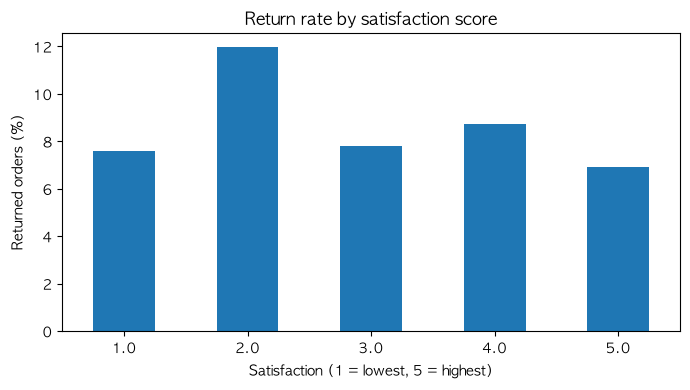

In [6]:
rated = df.dropna(subset=["satisfaction"]).copy()
rated["returned"] = rated["status"] == "반품"
return_summary = rated.groupby("satisfaction")["returned"].agg(
    returns="sum", orders="count", return_rate="mean"
)
return_summary["return_rate_percent"] = return_summary["return_rate"] * 100
print("⑥ Return rates by satisfaction level (%)")
display(return_summary[["returns", "orders", "return_rate_percent"]].round(2))

ax = return_summary["return_rate_percent"].plot.bar(figsize=(7, 4), rot=0)
ax.set_title("Return rate by satisfaction score")
ax.set_xlabel("Satisfaction (1 = lowest, 5 = highest)")
ax.set_ylabel("Returned orders (%)")
plt.tight_layout()
plt.show()


**⑥ Answer (two lines):** There is **no consistent decrease** in returns as satisfaction rises: level 1 has **7.59%**, level 2 **11.96%**, and level 5 **6.93%**.  
The highest return rate is at **satisfaction 2 (22/184 orders = 11.96%)**; therefore these data do **not** show a simple steadily increasing return rate as satisfaction gets lower.

## ⑦ Why is the top sales category ranked first?
**Question:** Compare categories using number of orders, total sales, average unit price, and average quantity. Use `groupby().agg()` and present the resulting table.

In [7]:
category_summary = df.groupby("category").agg(
    order_count=("total_sales", "size"),
    total_sales=("total_sales", "sum"),
    avg_unit_price=("unit_price", "mean"),
    avg_quantity=("quantity", "mean")
).sort_values("total_sales", ascending=False)
category_summary["total_sales_100m_krw"] = category_summary["total_sales"] / 100_000_000
print("⑦ Sales summary by category")
display(category_summary[[
    "order_count", "total_sales_100m_krw", "avg_unit_price", "avg_quantity"
]].round(2))


⑦ Sales summary by category


,order_count,total_sales_100m_krw,avg_unit_price,avg_quantity
category,,,,
가구,213,28.43,257322.91,51.04
식품,210,25.13,255232.93,47.31
전자제품,207,24.72,249651.61,47.96
도서,204,24.53,238500.64,49.50
의류,170,21.82,249447.16,51.61


**⑦ Answer (two lines):** **Furniture (가구)** ranks first with **28.43억 원** in total sales, compared with **Food (식품)** at **25.13억 원**.  
Their order counts (**213 vs 210**) and average unit prices (**₩257,323 vs ₩255,233**) are very similar, but Furniture has a higher **average quantity (51.04 vs 47.31)**. Among these three factors, average quantity shows the clearest difference from the second-place category; this helps explain Furniture’s lead without proving a single cause.